In [1]:
#IMPORT LIBS
import geopandas as gpd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from shapely.geometry import Point
import cartopy.util as cutil
import statsmodels.api as sm
from tqdm import tqdm
from scipy import stats

#my own classes
import sys
sys.path.append("/Users/michelefilippucci/Prog/github/blocktrack/lib")
import blocktoolbox as BT
sys.path.append("/Users/michelefilippucci/Prog/github/AtmBlockPy/lib")
import BlockPlots as BP

### FIRST LET'S CREATE A MASK OVER GREENLAND

### MASK 1
A mask with the shape of greenland

In [2]:
if False:

    # Load the world shapefile from GeoPandas datasets
    world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
    
    # Filter the dataset to only include Greenland
    greenland = world[world['name'] == 'Greenland'].explode(index_parts=False)
    
    # Define the resolution and create a grid of latitudes and longitudes
    lat_resolution = 2.5  # Resolution of 2.5 degrees
    lon_resolution = 2.5  # Resolution of 2.5 degrees
    
    # Define latitude and longitude ranges (rough bounds around Greenland)
    latitudes = np.arange(0, 91, lat_resolution)
    longitudes = np.arange(-180, +180, lon_resolution)

    # Define the rectangular bounding box around Greenland (60°–80°N, 20°–80°W)
    lat_min, lat_max = 60, 80
    lon_min, lon_max = -70, -20
    plon = (lon_min+lon_max)/2
    plat = (lat_min+lat_max)/2
    
    # Initialize a mask with zeros
    mask = np.zeros((len(latitudes), len(longitudes)))
    
    # Create the mask: 1 inside Greenland, 0 outside
    for i, lat in enumerate(latitudes):
        for j, lon in enumerate(longitudes):
            point = Point(lon, lat)
            if any(greenland.contains(point)):
                mask[i, j] = 1
    
    # Convert the mask to an xarray DataArray
    mask_xr = xr.DataArray(mask, coords=[latitudes, longitudes], dims=["lat", "lon"])
    mask_bool = mask_xr.data == 1

### MASK 2
A mask with rectangular shape

In [3]:
if True:

    # Define the resolution
    lat_resolution = 2.5  # 2.5 degrees
    lon_resolution = 2.5  # 2.5 degrees
    
    # Define the global latitude and longitude ranges
    latitudes = np.arange(0, 91, lat_resolution)  # From 0°N to 90°N
    longitudes = np.arange(-180, 180, lon_resolution)  # From -180°E to 180°E
    
    # Initialize a global mask with zeros
    mask = np.zeros((len(latitudes), len(longitudes)))
    
    # Define the rectangular bounding box around Greenland (60°–80°N, 20°–80°W)
    lat_min, lat_max = 60, 75
    lon_min, lon_max = -80, -20
    plon = (lon_min+lon_max)/2
    plat = (lat_min+lat_max)/2
    
    # Assign 1 to grid points within the bounding box
    for i, lat in enumerate(latitudes):
        if lat_min <= lat <= lat_max:
            for j, lon in enumerate(longitudes):
                if lon_min <= lon <= lon_max:
                    mask[i, j] = 1
    
    # Convert the mask to an xarray DataArray
    mask_xr = xr.DataArray(mask, coords=[latitudes, longitudes], dims=["lat", "lon"])
    mask_bool = mask_xr.data == 1

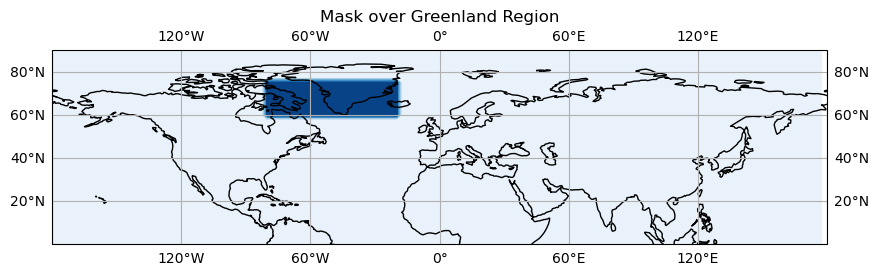

In [4]:
#LET's MAKE A PLOT TO VISUALIZE THE DOMAIN
# Plot the mask using Cartopy
plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-180, 180, 0, 90], crs=ccrs.PlateCarree())

# Plot the mask data
plt.contourf(mask_xr['lon'], mask_xr['lat'], mask_xr, cmap='Blues', transform=ccrs.PlateCarree())

# Add coastlines and gridlines
ax.add_feature(cfeature.COASTLINE)
ax.gridlines(draw_labels=True)

# Add title
plt.title('Mask over Greenland Region')

# Show the plot
plt.show()

### IMPORT BLOCKING DATA AND COMPUTE FREQUENCY

In [5]:
%cd /Users/michelefilippucci/Data/IFS/gr_tracking
!ls

/Users/michelefilippucci/Data/IFS/gr_tracking
IFS_northem_2.5x2.5_zg_DAV_tracked_daily_2020-2024.nc
IFS_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_2020-2024.nc
dictionaries


In [6]:
ds_filt_DAV = xr.open_dataset('IFS_northem_2.5x2.5_zg_DAV_tracked_daily_2020-2024.nc')
#ds_filt_GHA = xr.open_dataset('IFS_northem_2.5x2.5_zg_GHA_tracked_daily_2020-2024.nc')

In [7]:
%cd /Users/michelefilippucci/Data/IFS/gr_tracking/dictionaries/
!ls

/Users/michelefilippucci/Data/IFS/gr_tracking/dictionaries
IFS_northem_2.5x2.5_zg_DAV_tracked_daily_2020-2024_DIC.npy
IFS_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_2020-2024_DIC.npy


In [8]:
dic_for_filtering_DAV = np.load('IFS_northem_2.5x2.5_zg_DAV_tracked_daily_2020-2024_DIC.npy',allow_pickle=True) #original
#dic_for_filtering_GHA = np.load('IFS_northem_2.5x2.5_zg_GHA_tracked_daily_2020-2024_DIC.npy',allow_pickle=True) #original

In [9]:
#GHA_filt = ds_filt_GHA['GHA_tracked']
DAV_filt = ds_filt_DAV['DAV_tracked']
times = ds_filt_DAV['time']
lons = ds_filt_DAV['lon']
lats = ds_filt_DAV['lat']
months = ['06','07','08']

# Trajectories analysis

In [10]:
method = 'DAV'

if method == 'GHA':
    idxed = GHA_filt.values
    dic_for_filtering = dic_for_filtering_GHA
if method == 'DAV':
    idxed = DAV_filt.values
    dic_for_filtering = dic_for_filtering_DAV    
#create a list of indexes
indexes = []
timings = []
for t in tqdm(range(len(times.values)-5)):
    for l in np.unique(idxed[t,:,:])[1:]:
        month = str(dic_for_filtering[l]['date'])[5:7]
        check_cond = []
        for k in range(1):
            check_cond.append(np.any(idxed[t+k,mask_bool]==l))
        if l!=0 and l not in indexes and np.all(check_cond) and month in months:
            indexes.append(l)
            timings.append(t)
print(len(indexes))    

100%|████████████████████████████████████████████████████████████████| 1768/1768 [00:00<00:00, 13315.47it/s]

8


In [11]:
"""
A list of trajectories is then produced
"""
dic = []
for i,l in tqdm(enumerate(indexes)):
    dic.append({})
    dic[i]['track'] = dic_for_filtering[l]['track']
    dic[i]['area'] = sum(dic_for_filtering[l]['area'])/len(dic_for_filtering[l]['area'])
    dic[i]['date'] = dic_for_filtering[l]['date']
    dic[i]['avg_dist_traveled'] = sum(dic_for_filtering[l]['distance_traveled'])/len(dic_for_filtering[l]['distance_traveled'])

8it [00:00, 81840.08it/s]


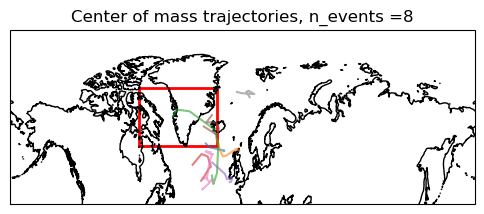

In [12]:
'''
TRAJECTORY PLOT
'''

import matplotlib.ticker as mticker

plt.figure(figsize=(6,6))

#dic =np.load("/Users/michelefilippucci/Prog/summer_greenland_block/data_tmp/dic_"+str(plon)+"-"+str(plat)+".npy",allow_pickle=True)
xs=[]
ys=[]
areas = []
for i in range(len(indexes)):
    #if 1959 == int(str(ds["time"].values[timings[i]])[0:4]):
    xs.append(dic[i]['track'][0])
    ys.append(dic[i]['track'][1])
    areas.append(dic[i]['area'])
output = "/home/mich/plots/POSTER/snapshots/trajectories.png"
#plot the trajectories to see what you are looking at
mapcrs = ccrs.PlateCarree()
datacrs = ccrs.PlateCarree()
extent =[-180,+180,45,90]
ax = plt.subplot(111, projection=mapcrs)
ax.set_extent(extent, datacrs)
ax.coastlines()
ax.set_aspect(3)

if True:
    # Plot the rectangle
    rect = plt.Rectangle((lon_min, lat_min), lon_max-lon_min, lat_max-lat_min,
                         edgecolor='red', facecolor='none', linewidth=2,
                         transform=ccrs.PlateCarree())
    ax.add_patch(rect)

for i in range(len(xs)):
    #print(len(xs[i]))
    cm = plt.plot(ys[i],xs[i],alpha=0.6,transform=datacrs)
#plt.text(30,60, 'n_events='+str(len(xs)), fontsize = 9)
plt.title('Center of mass trajectories, n_events =' + str(len(xs)), loc = 'center')


#plt.show()
#plt.savefig(output,bbox_inches='tight',dpi=400)
plt.savefig('/Users/michelefilippucci/PLOTS/EGU/trajectories.png',dpi=300)

In [13]:
xs=[]
ys=[]
areas = []
for i in range(len(indexes)):
    xs.append(dic[i]['track'][1])
    ys.append(dic[i]['track'][0])
    areas.append(dic[i]['area'])
#we want to store:
#-event label: dictionary key*
#-month
#-year
#-avg area in lifetime
#-initial distance from point
#-final distance from point 
#-duration
feature_dictionaries = []
for i,l in tqdm(enumerate(indexes)):
    event = {"label":l,
            "month":str(times.values[timings[i]])[5:7],
            "year":str(times.values[timings[i]])[0:4],
            "avg_area":np.mean(areas[i]),
            "duration":len(xs[i]),
            "initial_distance":((plon-xs[i][0])**2+(plat-ys[i][0])**2)**0.5,
            "final_distance":((plon-xs[i][-1])**2+(plat-ys[i][-1])**2)**0.5,
            "displacement_lon":plon-xs[i][0],
            "displacement_lat":plat-ys[i][0]
            }
    feature_dictionaries.append(event)

8it [00:00, 26757.92it/s]


In [14]:
print(feature_dictionaries[-1]['year'])

2024


In [15]:
areas_IFS = []
duration_IFS = []
distance_traveled_IFS = []
for event in feature_dictionaries:
    areas_IFS.append(event['avg_area'])
    duration_IFS.append(event['duration'])
    distance_traveled_IFS.append(np.sum(dic_for_filtering[event['label']]['distance_traveled']))


In [16]:
%cd /Users/michelefilippucci/Data/ERA5/gr_tracking
!ls

/Users/michelefilippucci/Data/ERA5/gr_tracking
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_djf_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1990.nc
dictionaries


In [17]:
ds_filt_DAV = xr.open_dataset('ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc')
ds_filt_GHA = xr.open_dataset('ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc')

In [18]:
%cd /Users/michelefilippucci/Data/ERA5/gr_tracking/dictionaries/
!ls

/Users/michelefilippucci/Data/ERA5/gr_tracking/dictionaries
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_DIC.npy
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1960-1963_DIC.npy
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023_DIC.npy
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1960-1963_DIC.npy
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023_DIC.npy
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1960-1963_DIC.npy
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1940-2023_DIC.npy
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1960-1963_DIC.npy


In [19]:
dic_for_filtering_DAV = np.load('ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_DIC.npy',allow_pickle=True) #original
dic_for_filtering_GHA = np.load('ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023_DIC.npy',allow_pickle=True) #original

In [20]:
GHA_filt = ds_filt_GHA['GHA_tracked']
DAV_filt = ds_filt_DAV['DAV_tracked']
times = ds_filt_DAV['time']
lons = ds_filt_DAV['lon']
lats = ds_filt_DAV['lat']

# Trajectories analysis

In [21]:
method = 'DAV'

if method == 'GHA':
    idxed = GHA_filt.values
    dic_for_filtering = dic_for_filtering_GHA
if method == 'DAV':
    idxed = DAV_filt.values
    dic_for_filtering = dic_for_filtering_DAV    
#create a list of indexes
indexes = []
timings = []
for t in tqdm(range(len(times.values)-5)):
    for l in np.unique(idxed[t,:,:])[1:]:
        month = str(dic_for_filtering[l]['date'])[5:7]
        check_cond = []
        for k in range(5):
            check_cond.append(np.any(idxed[t+k,mask_bool]==l))
        if l!=0 and l not in indexes and np.all(check_cond) and month in months:
            indexes.append(l)
            timings.append(t)
print(len(indexes))    

100%|███████████████████████████████████████████████████████████████| 30676/30676 [00:06<00:00, 5108.52it/s]

132


In [22]:
"""
A list of trajectories is then produced
"""
dic = []
for i,l in tqdm(enumerate(indexes)):
    dic.append({})
    dic[i]['track'] = dic_for_filtering[l]['track']
    dic[i]['area'] = sum(dic_for_filtering[l]['area'])/len(dic_for_filtering[l]['area'])
    dic[i]['date'] = dic_for_filtering[l]['date']
    dic[i]['avg_dist_traveled'] = sum(dic_for_filtering[l]['distance_traveled'])/len(dic_for_filtering[l]['distance_traveled'])

132it [00:00, 191573.75it/s]


Text(0.5, 1.0, 'Center of mass trajectories, n_events =132')

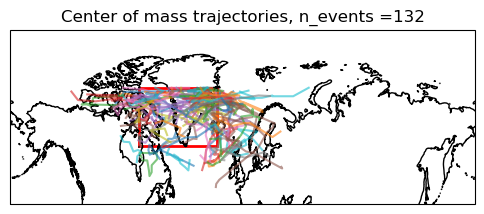

In [23]:
'''
TRAJECTORY PLOT
'''

import matplotlib.ticker as mticker

plt.figure(figsize=(6,6))

#dic =np.load("/Users/michelefilippucci/Prog/summer_greenland_block/data_tmp/dic_"+str(plon)+"-"+str(plat)+".npy",allow_pickle=True)
xs=[]
ys=[]
areas = []
for i in range(len(indexes)):
    #if 1959 == int(str(ds["time"].values[timings[i]])[0:4]):
    xs.append(dic[i]['track'][0])
    ys.append(dic[i]['track'][1])
    areas.append(dic[i]['area'])
output = "/home/mich/plots/POSTER/snapshots/trajectories.png"
#plot the trajectories to see what you are looking at
mapcrs = ccrs.PlateCarree()
datacrs = ccrs.PlateCarree()
extent =[-180,+180,45,90]
ax = plt.subplot(111, projection=mapcrs)
ax.set_extent(extent, datacrs)
ax.coastlines()
ax.set_aspect(3)

if True:
    # Plot the rectangle
    rect = plt.Rectangle((lon_min, lat_min), lon_max-lon_min, lat_max-lat_min,
                         edgecolor='red', facecolor='none', linewidth=2,
                         transform=ccrs.PlateCarree())
    ax.add_patch(rect)

for i in range(len(xs)):
    #print(len(xs[i]))
    cm = plt.plot(ys[i],xs[i],alpha=0.6,transform=datacrs)
#plt.text(30,60, 'n_events='+str(len(xs)), fontsize = 9)
plt.title('Center of mass trajectories, n_events =' + str(len(xs)), loc = 'center')


#plt.show()
#plt.savefig(output,bbox_inches='tight',dpi=400)
#plt.savefig('/Users/michelefilippucci/PLOTS/EGU/trajectories.png',dpi=300)

In [24]:
xs=[]
ys=[]
areas = []
for i in range(len(indexes)):
    xs.append(dic[i]['track'][1])
    ys.append(dic[i]['track'][0])
    areas.append(dic[i]['area'])
#we want to store:
#-event label: dictionary key*
#-month
#-year
#-avg area in lifetime
#-initial distance from point
#-final distance from point 
#-duration
feature_dictionaries = []
for i,l in tqdm(enumerate(indexes)):
    event = {"label":l,
            "month":str(times.values[timings[i]])[5:7],
            "year":str(times.values[timings[i]])[0:4],
            "avg_area":np.mean(areas[i]),
            "duration":len(xs[i]),
            "initial_distance":((plon-xs[i][0])**2+(plat-ys[i][0])**2)**0.5,
            "final_distance":((plon-xs[i][-1])**2+(plat-ys[i][-1])**2)**0.5,
            "displacement_lon":plon-xs[i][0],
            "displacement_lat":plat-ys[i][0]
            }
    feature_dictionaries.append(event)

132it [00:00, 51723.48it/s]


In [25]:
areas_ERA5 = []
duration_ERA5 = []
distance_traveled_ERA5 = []
for event in feature_dictionaries:
    areas_ERA5.append(event['avg_area'])
    duration_ERA5.append(event['duration'])
    distance_traveled_ERA5.append(np.sum(dic_for_filtering[event['label']]['distance_traveled']))


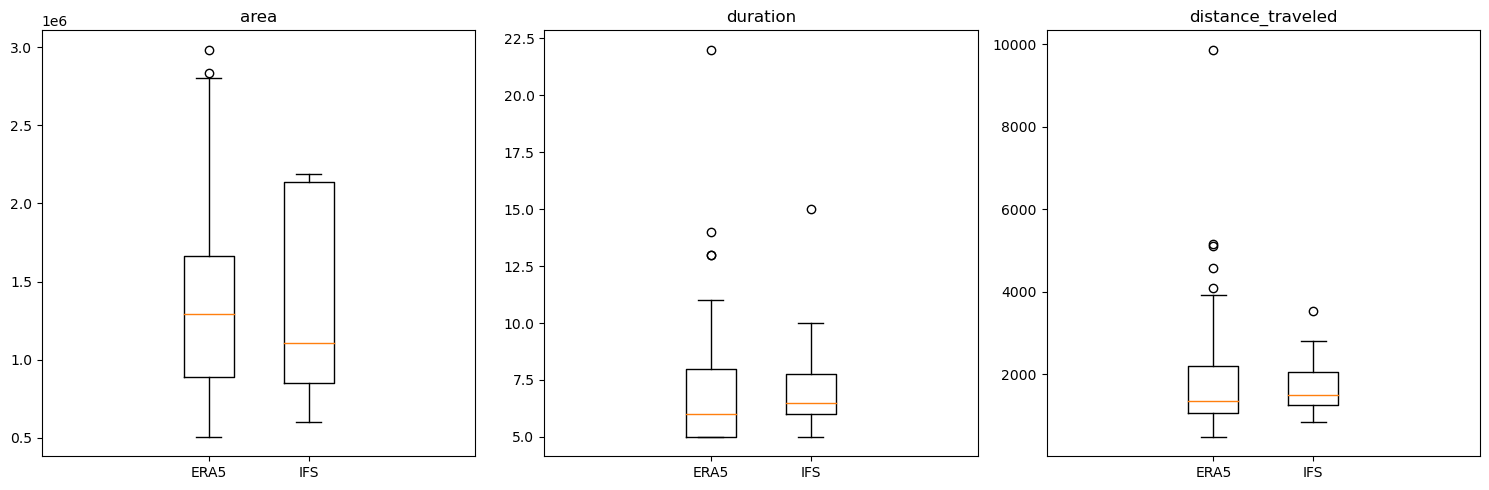

In [26]:
# Create a figure with 1 row and 3 columns
fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))

# Plot data on each subplot
axs[0].boxplot(areas_ERA5,positions=[1],labels=['ERA5'])
axs[0].boxplot(areas_IFS,positions=[1.3],labels=['IFS'])
axs[0].set_title('area')

# Plot data on each subplot
axs[1].boxplot(duration_ERA5,positions=[1],labels=['ERA5'])
axs[1].boxplot(duration_IFS,positions=[1.3],labels=['IFS'])
axs[1].set_title('duration')

# Plot data on each subplot
axs[2].boxplot(distance_traveled_ERA5,positions=[1],labels=['ERA5'])
axs[2].boxplot(distance_traveled_IFS,positions=[1.3],labels=['IFS'])
axs[2].set_title('distance_traveled')

# Add overall title and labels (optional)
plt.tight_layout()  # Adjust layout to prevent overlapping

# Show the plot
plt.show()

In [27]:
#frequency:
ERA5_freq = len(areas_ERA5)/83
IFS_freq = len(areas_IFS)/5

print('ERA5 events/year: ' + str(ERA5_freq))
print('IFS events/year: ' + str(IFS_freq))

ERA5 events/year: 1.5903614457831325
IFS events/year: 1.6
